# code_082 · Distances metrics and meaningful neighbourhoods

**Book:** section 17.1. A self-contained similarity-and-margin laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_17_GUIDE.md), [run evidence](../CHAPTER_17_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_082).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1782;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1782


<a id="units"></a>
## Stored numeric units are part of a naive distance

A fixed query is40000N load,4m span,steel. Four complete structures A/B/C/D have load/span[40200,2],[41000,4.1],[38000,3.7],[50000,4], materials steel/steel/concrete/steel. Compare raw Euclidean numeric distance with declared dimensionless scales50000N and2m. These are reference choices, not fitted physical similarity laws. Raw force conversion to kN can change a naive ranking; consistently converted dimensionless features preserve it. Plots retain the same four complete records and annotate the computed metric; contours show distances despite different display axes. No target prediction or deployment accuracy is claimed by this geometry audit.


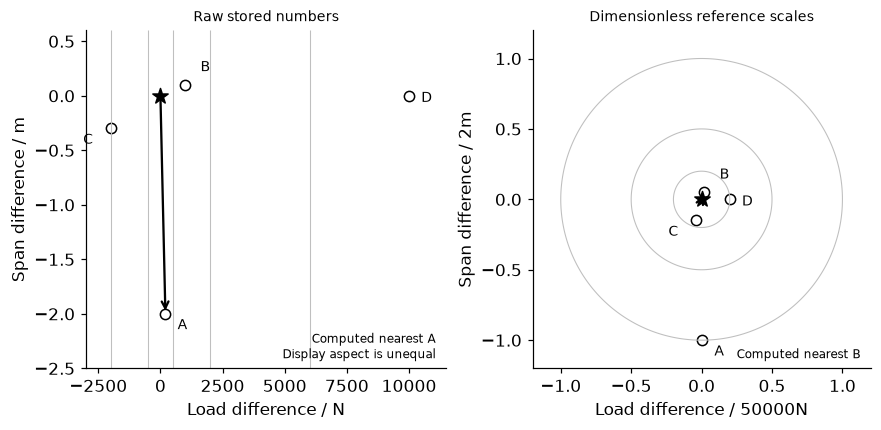

In [2]:
query=np.array([40000.,4]);X=np.array([[40200.,2],[41000.,4.1],[38000.,3.7],[50000.,4]]);names=np.array(['A','B','C','D']);reference=np.array([50000.,2]);delta=X-query;raw=np.linalg.norm(delta,axis=1);scaled=np.linalg.norm(delta/reference,axis=1);raw_kN=np.linalg.norm(delta/np.array([1000.,1]),axis=1);scaled_kN=np.linalg.norm((delta/np.array([1000.,1]))/(reference/np.array([1000.,1])),axis=1)
assert names[np.argmin(raw)]=='A' and names[np.argmin(scaled)]=='B';assert np.argmin(raw_kN)!=np.argmin(raw);np.testing.assert_allclose(scaled,scaled_kN)
RESULTS['geometry']={'names':names.tolist(),'raw_N_m_numeric_distances':raw.tolist(),'raw_kN_m_numeric_distances':raw_kN.tolist(),'dimensionless_distances':scaled.tolist(),'raw_nearest':str(names[np.argmin(raw)]),'dimensionless_nearest':str(names[np.argmin(scaled)]),'dimensionless_unit_invariance_passed':True,'reference_load_N':50000,'reference_span_m':2}
fig,axes=plt.subplots(1,2,figsize=(8,3.8))
for ax,a,nearest,title in [(axes[0],delta,0,'Raw stored numbers'),(axes[1],delta/reference,1,'Dimensionless reference scales')]:
 ax.scatter(a[:,0],a[:,1],s=45,facecolors='white',edgecolors='black');ax.scatter([0],[0],marker='*',s=110,color='black');offsets=[(8,-10),(10,9),(-18,-10),(8,-4)]
 for label,xy,offset in zip(names,a,offsets):ax.annotate(label,xy,xytext=offset,textcoords='offset points',fontsize=9)
 ax.annotate('',xy=a[nearest],xytext=(0,0),arrowprops=dict(arrowstyle='->',color='black',lw=1.5));ax.set(title=title)
axes[0].set(xlabel='Load difference / N',ylabel='Span difference / m',xlim=(-3000,11500),ylim=(-2.5,.6));xx,yy=np.meshgrid(np.linspace(-3000,11500,200),np.linspace(-2.5,.6,100));axes[0].contour(xx,yy,np.sqrt(xx**2+yy**2),levels=[500,2000,6000],colors='.75',linewidths=.7);axes[0].text(.97,.03,'Computed nearest A\nDisplay aspect is unequal',transform=axes[0].transAxes,ha='right',fontsize=8)
axes[1].set(xlabel='Load difference / 50000N',ylabel='Span difference / 2m',xlim=(-1.2,1.2),ylim=(-1.2,1.2),aspect='equal');xx,yy=np.meshgrid(np.linspace(-1.2,1.2,180),np.linspace(-1.2,1.2,180));axes[1].contour(xx,yy,np.sqrt(xx**2+yy**2),levels=[.2,.5,1],colors='.75',linewidths=.7);axes[1].text(.97,.03,'Computed nearest B',transform=axes[1].transAxes,ha='right',fontsize=8);plt.show()


<a id="mixed"></a>
## A perfect match on one available field can be weak evidence

Add E with load40000N, missing span,steel, and F with no numeric/material observations. The custom mixed distance averages available normalized absolute numeric differences and a categorical mismatch indicator; it is a declared teaching rule, not a complete Gower package. E has zero distance on its two shared fields, but eligibility here requires all three fields, so E is excluded. F has no comparable fields and returns None rather than zero. Separately fit a covariance to eighty admitted training load/span records with declared10%diagonal shrinkage. Mahalanobis distances are invariant when data and covariance units change consistently. That geometric invariance does not justify the covariance as a mechanical notion of similarity.


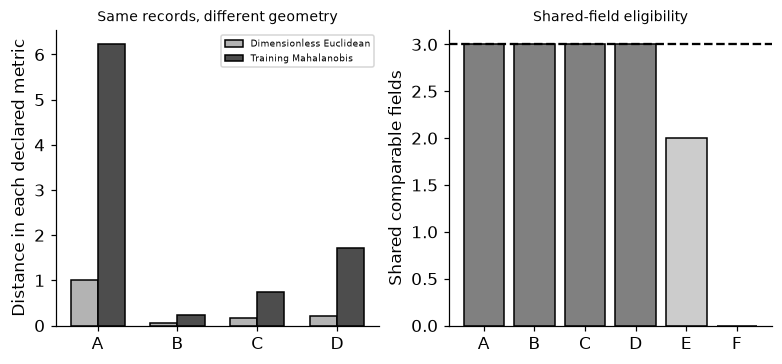

In [3]:
materials=['steel','steel','concrete','steel','steel',None];extended=np.vstack([X,[40000,np.nan],[np.nan,np.nan]]);mixed=[]
for label,row,material in zip(list(names)+['E','F'],extended,materials):
 observed=np.isfinite(row);values=list(np.abs((row[observed]-query[observed])/reference[observed]));
 if material is not None:values.append(float(material!='steel'))
 count=len(values);mixed.append({'record':str(label),'shared_fields':count,'distance':float(np.mean(values)) if count else None,'eligible_all_three_fields':count==3})
assert mixed[-2]['distance']==0 and not mixed[-2]['eligible_all_three_fields'];assert mixed[-1]['distance'] is None
z=rng.normal(size=(80,2));training=np.column_stack([40000+8000*z[:,0],4+.35*z[:,0]+.3*z[:,1]])
def covariance(a):
 c=np.cov(a,rowvar=False);return .9*c+.1*np.diag(np.diag(c))
C=covariance(training);mahal=np.sqrt(np.sum(np.linalg.solve(C,delta.T).T*delta,axis=1));converted=training/np.array([1000,1]);d=delta/np.array([1000,1]);converted_distance=np.sqrt(np.sum(np.linalg.solve(covariance(converted),d.T).T*d,axis=1));np.testing.assert_allclose(mahal,converted_distance,atol=1e-12)
RESULTS['mixed_missing']=mixed;RESULTS['training_covariance_metric']={'fit_rows':80,'diagonal_shrinkage':.1,'Mahalanobis_distances':mahal.tolist(),'unit_conversion_invariance_passed':True}
# Independent nuisance dimensions can dominate a geometric neighborhood even after unit scaling.
probe=rng.normal(size=(200,2));d2=np.linalg.norm(probe,axis=1);expanded=np.column_stack([probe,rng.normal(size=(200,50))]);d52=np.linalg.norm(expanded,axis=1)
RESULTS['irrelevant_dimensions']={'records':200,'signal_dimensions':2,'extra_independent_noise_dimensions':50,'distance_CV_2d':float(d2.std()/d2.mean()),'distance_CV_52d':float(d52.std()/d52.mean()),'top5_neighbor_overlap':len(set(np.argsort(d2)[:5])&set(np.argsort(d52)[:5]))/5,'query':'origin in both spaces; diagnostic geometry only'}

fig,axes=plt.subplots(1,2,figsize=(7,3.2));positions=np.arange(4)
for j,(label,value) in enumerate([('Dimensionless Euclidean',scaled),('Training Mahalanobis',mahal)]):axes[0].bar(positions+(j-.5)*.34,value,width=.34,color=['.7','.3'][j],edgecolor='black',label=label)
axes[0].set(xticks=positions,xticklabels=names,ylabel='Distance in each declared metric',title='Same records, different geometry');axes[0].legend(fontsize=6)
axes[1].bar(range(6),[v['shared_fields'] for v in mixed],color=['.5']*4+['.8','.95'],edgecolor='black');axes[1].axhline(3,color='black',ls='--');axes[1].set(xticks=range(6),xticklabels=list(names)+['E','F'],ylabel='Shared comparable fields',title='Shared-field eligibility');plt.show()


In [4]:
summary={'example_id':'code_082','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['raw units versus dimensionless reference scales', 'unit-consistent Mahalanobis covariance', 'categorical and missing shared features', 'distance eligibility and neighborhood geometry'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["raw units versus dimensionless reference scales", "unit-consistent Mahalanobis covariance", "categorical and missing shared features", "distance eligibility and neighborhood geometry"], "elapsed_seconds": 0.209, "example_id": "code_082", "hardware": "Darwin arm64 CPU", "results": {"geometry": {"dimensionless_distances": [1.0000079999680003, 0.053851648071344876, 0.15524174696260015, 0.2], "dimensionless_nearest": "B", "dimensionless_unit_invariance_passed": true, "names": ["A", "B", "C", "D"], "raw_N_m_numeric_distances": [200.0099997500125, 1000.000005, 2000.0000225, 10000.0], "raw_kN_m_numeric_distances": [2.009975124224178, 1.004987562112089, 2.0223748416156684, 10.0], "raw_nearest": "A", "reference_load_N": 50000, "reference_span_m": 2}, "irrelevant_dimensions": {"distance_CV_2d": 0.4983022081056885, "distance_CV_52d": 0.09800329216737635, "extra_independent_noise_dimensions": 50, "query": "origin in both spaces; diagnostic geometr